# Netflix Content Patterns Project
# Week 6: Feature Engineering

## Objective

The objective of Week 6 is to prepare the Netflix dataset
for advanced analysis by applying feature engineering
techniques.

The major activities include:
- Extracting numerical features.
- Encoding categorical variables.
- Handling skewness.
- Applying feature scaling and normalization.

These techniques help convert the dataset into a
numerical format suitable for further analysis and PCA.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
    PowerTransformer
)

sns.set_style("whitegrid")

## Step 1: Loading the Dataset

The original Netflix dataset is loaded using Pandas.

The missing-value handling strategies used in Week 3
are applied again to maintain consistency.

The original dataset is preserved, and a separate
working copy is created for feature engineering.

In [2]:
df = pd.read_csv("netflix_titles.csv")

print("Original Dataset Shape:", df.shape)

# Create a working copy
df = df.copy()

# Handle missing categorical values
for col in ['director', 'cast', 'country']:
    df[col] = df[col].fillna('Unknown')

# Fill missing rating with mode
mode_rating = df['rating'].mode()[0]
df['rating'] = df['rating'].fillna(mode_rating)

# Convert date_added into datetime
df['date_added'] = pd.to_datetime(
    df['date_added'].str.strip(),
    errors='coerce'
)

print("\nMissing Values:")
print(df.isnull().sum())

df.head()

Original Dataset Shape: (8807, 12)

Missing Values:
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         3
listed_in        0
description      0
dtype: int64


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


## Step 2: Feature Extraction

Feature extraction is the process of creating useful
numerical variables from existing dataset columns.

In the Netflix dataset, the duration column contains
both movie durations in minutes and TV Show durations
in seasons.

Therefore, we extract:
1. Movie Duration in Minutes.
2. Number of TV Show Seasons.
3. Netflix Addition Year.

These features help us analyze content characteristics
and binge-watch potential.

In [3]:
# Extract numerical value from duration
df['duration_num'] = pd.to_numeric(
    df['duration'].str.extract(r'(\d+)')[0],
    errors='coerce'
)

# Separate movie duration and TV seasons
df['movie_duration_min'] = np.where(
    df['type'] == 'Movie',
    df['duration_num'],
    np.nan
)

df['tv_seasons'] = np.where(
    df['type'] == 'TV Show',
    df['duration_num'],
    np.nan
)

# Extract Netflix addition year
df['added_year'] = df['date_added'].dt.year

# Display newly created features
df[['type', 'duration',
    'movie_duration_min',
    'tv_seasons',
    'added_year']].head(10)

,type,duration,movie_duration_min,tv_seasons,added_year
0,Movie,90 min,90.0,NaN,2021.0
1,TV Show,2 Seasons,NaN,2.0,2021.0
2,TV Show,1 Season,NaN,1.0,2021.0
3,TV Show,1 Season,NaN,1.0,2021.0
4,TV Show,2 Seasons,NaN,2.0,2021.0
5,TV Show,1 Season,NaN,1.0,2021.0
6,Movie,91 min,91.0,NaN,2021.0
7,Movie,125 min,125.0,NaN,2021.0
8,TV Show,9 Seasons,NaN,9.0,2021.0
9,Movie,104 min,104.0,NaN,2021.0


## Step 3: Handling Missing Numerical Values

Some numerical features contain missing values.

Movie duration is applicable only to Movies, while
season count is applicable only to TV Shows.

Therefore, missing values are handled separately
according to content type.

The median is selected for actual missing duration
values because it is less affected by extreme values
than the mean.

Zero is assigned to the feature that is not applicable
to a particular content type.

In [4]:
# Impute missing movie duration using movie median
movie_median = df.loc[
    df['type'] == 'Movie',
    'movie_duration_min'
].median()

df.loc[
    (df['type'] == 'Movie') &
    (df['movie_duration_min'].isnull()),
    'movie_duration_min'
] = movie_median


# Impute missing TV seasons using TV Show median
tv_median = df.loc[
    df['type'] == 'TV Show',
    'tv_seasons'
].median()

df.loc[
    (df['type'] == 'TV Show') &
    (df['tv_seasons'].isnull()),
    'tv_seasons'
] = tv_median


# Zero means the feature is not applicable
df['movie_duration_min'] = df[
    'movie_duration_min'
].fillna(0)

df['tv_seasons'] = df[
    'tv_seasons'
].fillna(0)

# Handle missing addition year using median
df['added_year'] = df['added_year'].fillna(
    df['added_year'].median()
)

print("Missing numerical values:")
print(df[
    ['movie_duration_min', 'tv_seasons', 'added_year']
].isnull().sum())

Missing numerical values:
movie_duration_min    0
tv_seasons            0
added_year            0
dtype: int64


## Step 4: Encoding Categorical Variables

Machine learning algorithms require numerical input.

However, the Netflix dataset contains categorical
variables such as:
- Content Type
- Rating
- Genre

One-Hot Encoding is used to convert these categories
into numerical binary columns.

The top 10 genres are selected to create genre-based
features.

This avoids creating an excessively large number
of columns from all available genres.

In [5]:
# One-hot encode content type
type_encoded = pd.get_dummies(
    df['type'],
    prefix='type',
    dtype=int
)

# One-hot encode content rating
rating_encoded = pd.get_dummies(
    df['rating'],
    prefix='rating',
    dtype=int
)

# Extract top 10 genres
genre_series = df['listed_in'].dropna().str.split(', ').explode()

top_genres = genre_series.value_counts().head(10).index

# Create binary genre features
genre_features = pd.DataFrame(
    {
        'genre_' + genre: df['listed_in'].fillna('').apply(
            lambda x: int(genre in x.split(', '))
        )
        for genre in top_genres
    },
    index=df.index
)

# Combine encoded features
encoded_df = pd.concat(
    [type_encoded, rating_encoded, genre_features],
    axis=1
)

print("Encoded Dataset:")
display(encoded_df.head())

print("\nNumber of encoded features:", encoded_df.shape[1])

Encoded Dataset:


,type_Movie,type_TV Show,rating_66 min,rating_74 min,rating_84 min,rating_G,rating_NC-17,rating_NR,rating_PG,rating_PG-13,...,genre_International Movies,genre_Dramas,genre_Comedies,genre_International TV Shows,genre_Documentaries,genre_Action & Adventure,genre_TV Dramas,genre_Independent Movies,genre_Children & Family Movies,genre_Romantic Movies
0,1,0,0,0,0,0,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
1,0,1,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,1,0,0,0
2,0,1,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
3,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,1,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0



Number of encoded features: 29


## Step 5: Creating the Feature Engineered Dataset

The numerical features and encoded categorical
features are combined into a single dataset.

The selected features include:
- Release Year
- Netflix Addition Year
- Movie Duration
- TV Show Seasons
- Content Type
- Ratings
- Top 10 Genres

The resulting dataset contains numerical values
that can be used for scaling and PCA.

In [6]:
# Select numerical features
numerical_features = df[
    [
        'release_year',
        'added_year',
        'movie_duration_min',
        'tv_seasons'
    ]
].copy()

# Combine numerical and encoded features
feature_df = pd.concat(
    [numerical_features, encoded_df],
    axis=1
)

print("Feature Engineered Dataset Shape:")
print(feature_df.shape)

display(feature_df.head())

Feature Engineered Dataset Shape:
(8807, 33)


,release_year,added_year,movie_duration_min,tv_seasons,type_Movie,type_TV Show,rating_66 min,rating_74 min,rating_84 min,rating_G,...,genre_International Movies,genre_Dramas,genre_Comedies,genre_International TV Shows,genre_Documentaries,genre_Action & Adventure,genre_TV Dramas,genre_Independent Movies,genre_Children & Family Movies,genre_Romantic Movies
0,2020,2021.0,90.0,0.0,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
1,2021,2021.0,0.0,2.0,0,1,0,0,0,0,...,0,0,0,1,0,0,1,0,0,0
2,2021,2021.0,0.0,1.0,0,1,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
3,2021,2021.0,0.0,1.0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2021,2021.0,0.0,2.0,0,1,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0


## Step 6: Skewness Analysis

Skewness measures the asymmetry of a numerical
distribution.

Types of skewness:

1. Positive Skewness:
   The tail extends towards the right.

2. Negative Skewness:
   The tail extends towards the left.

3. Zero Skewness:
   The distribution is approximately symmetric.

Skewness is calculated before applying transformations
to identify features that require adjustment.

In [7]:
numeric_cols = [
    'release_year',
    'added_year',
    'movie_duration_min',
    'tv_seasons'
]

skew_before = feature_df[numeric_cols].skew()

print("Skewness Before Transformation:")
print(skew_before)

Skewness Before Transformation:
release_year         -3.446565
added_year           -0.705349
movie_duration_min   -0.206263
tv_seasons            4.359961
dtype: float64


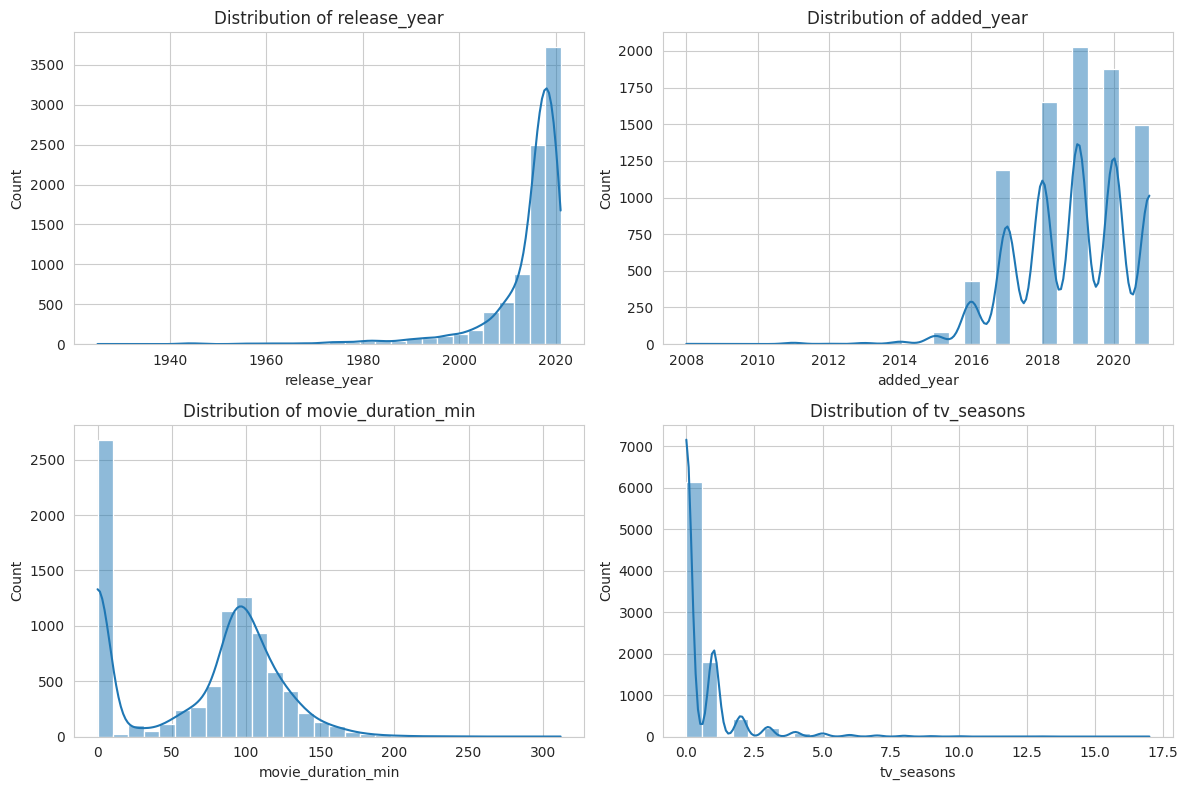

In [8]:
plt.figure(figsize=(12, 8))

for i, col in enumerate(numeric_cols):
    plt.subplot(2, 2, i + 1)

    sns.histplot(
        feature_df[col],
        kde=True,
        bins=30
    )

    plt.title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

## Step 7: Skewness Transformation

Yeo-Johnson transformation is applied to numerical
features to reduce skewness.

It is selected because it can handle positive values,
negative values, and zero values.

Unlike Log Transformation, it does not require
all values to be strictly positive.

The skewness values are compared before and after
transformation to evaluate its effectiveness.

In [11]:
# Step 1: Create an empty DataFrame
transformed_df = pd.DataFrame(
    index=feature_df.index
)

# Step 2: Apply Yeo-Johnson transformation
# separately to each numerical feature

for col in numeric_cols:

    values = feature_df[col].astype(float)

    # Movie duration and TV seasons
    # Zero means the feature is not applicable
    if col in ['movie_duration_min', 'tv_seasons']:

        transformed_df[col] = 0.0

        # Select only applicable positive values
        mask = values > 0

        transformer = PowerTransformer(
            method='yeo-johnson',
            standardize=False
        )

        transformed_df.loc[mask, col] = (
            transformer.fit_transform(
                values[mask].values.reshape(-1, 1)
            ).flatten()
        )

    else:

        # Center year values around their median
        centered_values = (
            values - values.median()
        )

        transformer = PowerTransformer(
            method='yeo-johnson',
            standardize=False
        )

        transformed_df[col] = (
            transformer.fit_transform(
                centered_values.values.reshape(-1, 1)
            ).flatten()
        )


# Step 3: Calculate skewness after transformation
skew_after = transformed_df.skew()

# Step 4: Compare before and after
skew_comparison = pd.DataFrame({
    'Before Transformation': skew_before,
    'After Transformation': skew_after
})

print("Skewness Comparison:")
display(skew_comparison.round(3))

Skewness Comparison:


,Before Transformation,After Transformation
release_year,-3.447,-0.065
added_year,-0.705,-0.092
movie_duration_min,-0.206,-0.225
tv_seasons,4.360,0.864


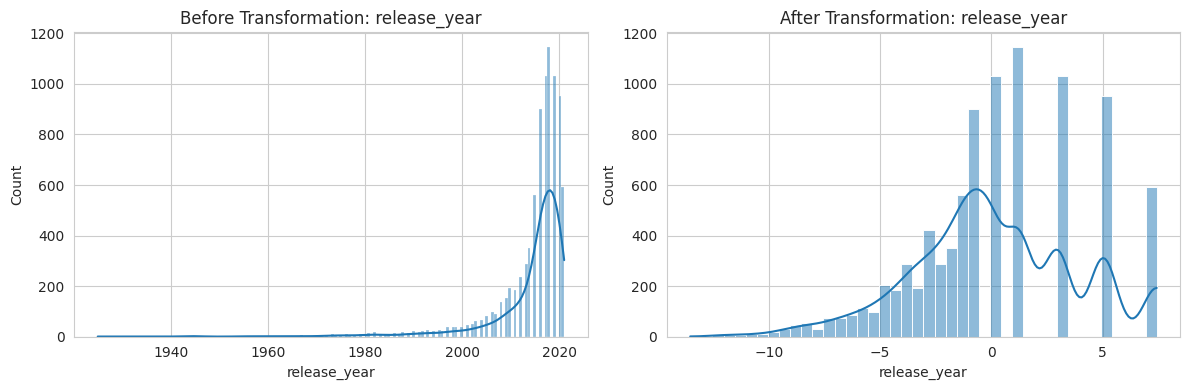

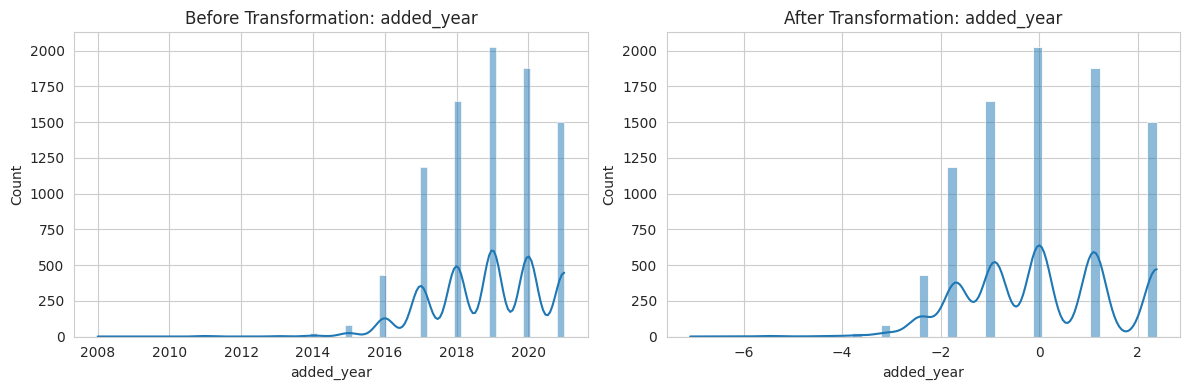

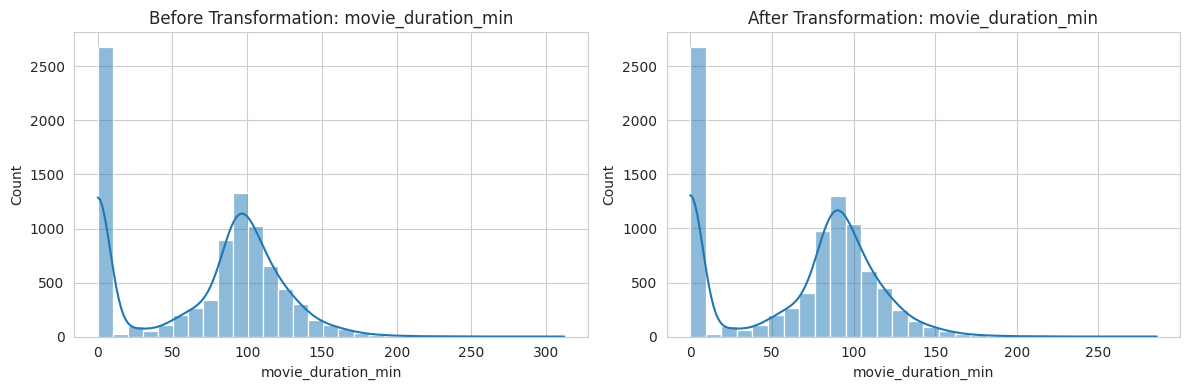

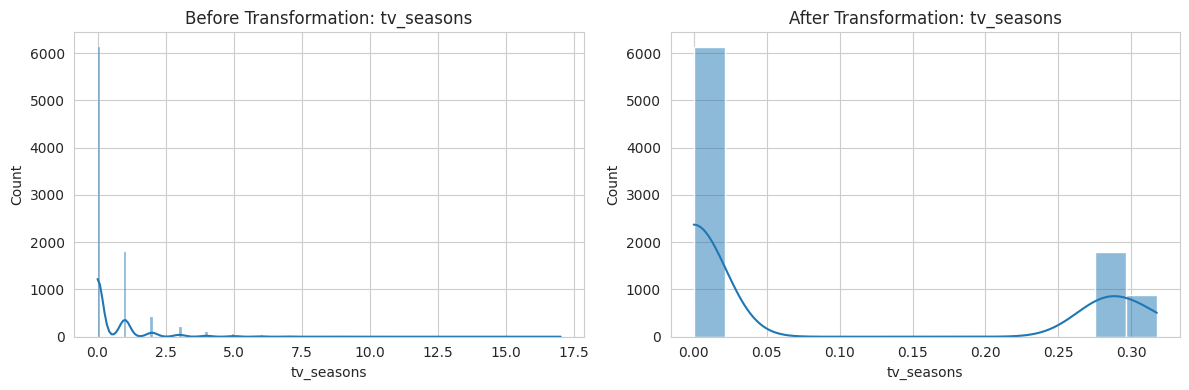

In [12]:
for col in numeric_cols:

    fig, axes = plt.subplots(
        1, 2, figsize=(12, 4)
    )

    sns.histplot(
        feature_df[col],
        kde=True,
        ax=axes[0]
    )

    axes[0].set_title(
        f"Before Transformation: {col}"
    )

    sns.histplot(
        transformed_df[col],
        kde=True,
        ax=axes[1]
    )

    axes[1].set_title(
        f"After Transformation: {col}"
    )

    plt.tight_layout()
    plt.show()

In [13]:
print("Before Transformation:")
print(feature_df[numeric_cols].skew())

print("\nAfter Transformation:")
print(transformed_df.skew())

print("\nChecking Infinite Values:")
print(np.isinf(transformed_df).sum())

print("\nChecking Missing Values:")
print(transformed_df.isnull().sum())

Before Transformation:
release_year         -3.446565
added_year           -0.705349
movie_duration_min   -0.206263
tv_seasons            4.359961
dtype: float64

After Transformation:
release_year         -0.065413
added_year           -0.092438
movie_duration_min   -0.225064
tv_seasons            0.864404
dtype: float64

Checking Infinite Values:
release_year          0
added_year            0
movie_duration_min    0
tv_seasons            0
dtype: int64

Checking Missing Values:
release_year          0
added_year            0
movie_duration_min    0
tv_seasons            0
dtype: int64


## Step 8: Normalization using MinMaxScaler

Normalization is a feature scaling technique used
to convert numerical values into a fixed range
between 0 and 1.

Formula:

X_scaled = (X - X_min) / (X_max - X_min)

In this project, MinMaxScaler is applied to the
transformed numerical features.

This helps bring features with different ranges
into a common scale.

In [14]:
from sklearn.preprocessing import MinMaxScaler

# Create MinMaxScaler object
minmax_scaler = MinMaxScaler()

# Apply normalization
minmax_scaled = minmax_scaler.fit_transform(
    transformed_df[numeric_cols]
)

# Convert into DataFrame
minmax_df = pd.DataFrame(
    minmax_scaled,
    columns=numeric_cols,
    index=transformed_df.index
)

print("MinMax Scaled Dataset:")
display(minmax_df.head())

print("\nMinimum Values:")
print(minmax_df.min())

print("\nMaximum Values:")
print(minmax_df.max())

MinMax Scaled Dataset:


,release_year,added_year,movie_duration_min,tv_seasons
0,0.885705,1.0,0.294961,0.000000
1,1.000000,1.0,0.000000,0.968679
2,1.000000,1.0,0.000000,0.887400
3,1.000000,1.0,0.000000,0.887400
4,1.000000,1.0,0.000000,0.968679



Minimum Values:
release_year          0.0
added_year            0.0
movie_duration_min    0.0
tv_seasons            0.0
dtype: float64

Maximum Values:
release_year          1.0
added_year            1.0
movie_duration_min    1.0
tv_seasons            1.0
dtype: float64


## Step 9: Standardization using StandardScaler

Standardization is a scaling technique that
transforms numerical features to have:

Mean = 0
Standard Deviation = 1

Formula:

Z = (X - Mean) / Standard Deviation

StandardScaler is applied to the transformed
numerical features.

This technique is particularly important for
PCA because PCA is sensitive to differences
in feature scales.

In [15]:
from sklearn.preprocessing import StandardScaler

# Create StandardScaler object
standard_scaler = StandardScaler()

# Apply standardization
standard_scaled = standard_scaler.fit_transform(
    transformed_df[numeric_cols]
)

# Convert into DataFrame
standard_df = pd.DataFrame(
    standard_scaled,
    columns=numeric_cols,
    index=transformed_df.index
)

print("Standardized Dataset:")
display(standard_df.head())

print("\nMean:")
print(standard_df.mean().round(3))

print("\nStandard Deviation:")
print(standard_df.std(ddof=0).round(3))

Standardized Dataset:


,release_year,added_year,movie_duration_min,tv_seasons
0,1.290870,1.535004,0.407228,-0.659543
1,1.926734,1.535004,-1.350050,1.630178
2,1.926734,1.535004,-1.350050,1.438054
3,1.926734,1.535004,-1.350050,1.438054
4,1.926734,1.535004,-1.350050,1.630178



Mean:
release_year         -0.0
added_year            0.0
movie_duration_min    0.0
tv_seasons           -0.0
dtype: float64

Standard Deviation:
release_year          1.0
added_year            1.0
movie_duration_min    1.0
tv_seasons            1.0
dtype: float64


## Step 10: Comparison of Scaling Techniques

MinMaxScaler and StandardScaler are compared
to understand how different scaling methods
affect numerical features.

MinMaxScaler converts values into the range
of 0 to 1.

StandardScaler transforms values to have
approximately zero mean and unit variance.

Both techniques are useful for preparing
data for machine learning algorithms.

In [16]:
scaling_comparison = pd.DataFrame({
    'Original': transformed_df['release_year'],
    'MinMax Scaled': minmax_df['release_year'],
    'Standard Scaled': standard_df['release_year']
})

display(scaling_comparison.head(10))

,Original,MinMax Scaled,Standard Scaled
0,5.030862,0.885705,1.290870
1,7.427335,1.000000,1.926734
2,7.427335,1.000000,1.926734
3,7.427335,1.000000,1.926734
4,7.427335,1.000000,1.926734
5,7.427335,1.000000,1.926734
6,7.427335,1.000000,1.926734
7,-6.802157,0.321350,-1.848825
8,7.427335,1.000000,1.926734
9,7.427335,1.000000,1.926734


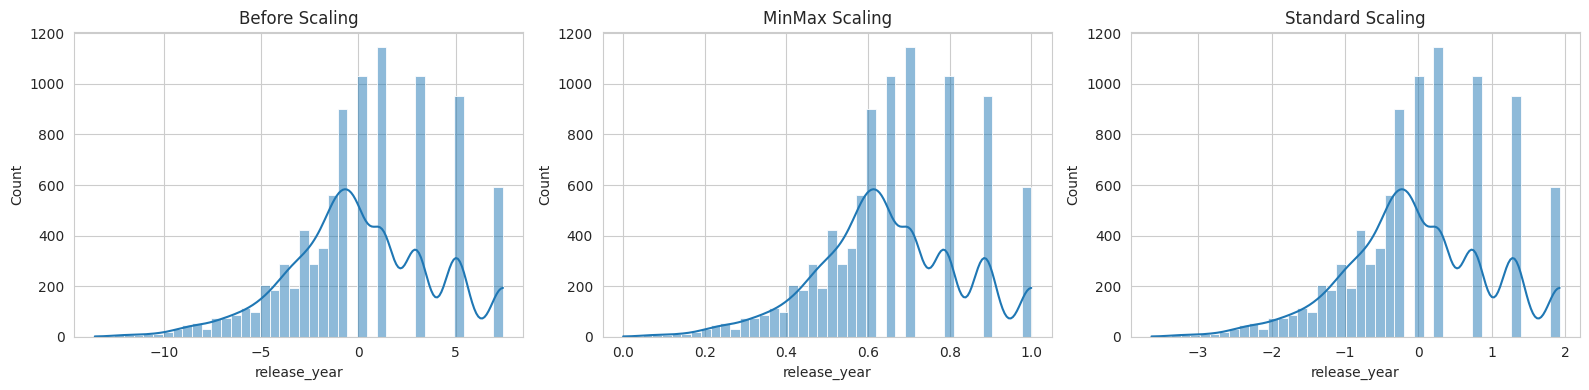

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(
    transformed_df['release_year'],
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Before Scaling")

sns.histplot(
    minmax_df['release_year'],
    kde=True,
    ax=axes[1]
)
axes[1].set_title("MinMax Scaling")

sns.histplot(
    standard_df['release_year'],
    kde=True,
    ax=axes[2]
)
axes[2].set_title("Standard Scaling")

plt.tight_layout()
plt.show()

## Step 11: Final Feature Engineered Dataset

The transformed numerical features and encoded
categorical features are combined into one
final dataset.

This dataset contains numerical representations
of Netflix content characteristics.

The final feature-engineered dataset will be
used as the input for Week 7 dimensionality
reduction using PCA.

In [18]:
# Combine transformed numerical features
# and encoded categorical features

week6_final = pd.concat(
    [
        transformed_df,
        encoded_df
    ],
    axis=1
)

print("Final Week 6 Dataset Shape:")
print(week6_final.shape)

print("\nFinal Dataset:")
display(week6_final.head())

Final Week 6 Dataset Shape:
(8807, 33)

Final Dataset:


,release_year,added_year,movie_duration_min,tv_seasons,type_Movie,type_TV Show,rating_66 min,rating_74 min,rating_84 min,rating_G,...,genre_International Movies,genre_Dramas,genre_Comedies,genre_International TV Shows,genre_Documentaries,genre_Action & Adventure,genre_TV Dramas,genre_Independent Movies,genre_Children & Family Movies,genre_Romantic Movies
0,5.030862,2.38331,84.264815,0.000000,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
1,7.427335,2.38331,0.000000,0.307536,0,1,0,0,0,0,...,0,0,0,1,0,0,1,0,0,0
2,7.427335,2.38331,0.000000,0.281732,0,1,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
3,7.427335,2.38331,0.000000,0.281732,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,7.427335,2.38331,0.000000,0.307536,0,1,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0


In [19]:
print("Missing Values:")
print(week6_final.isnull().sum().sum())

print("\nInfinite Values:")
print(np.isinf(week6_final.select_dtypes(
    include=np.number
)).sum().sum())

print("\nDuplicate Rows:")
print(week6_final.duplicated().sum())

print("\nDataset Information:")
week6_final.info()

Missing Values:
0

Infinite Values:
0

Duplicate Rows:
1897

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 33 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   release_year                    8807 non-null   float64
 1   added_year                      8807 non-null   float64
 2   movie_duration_min              8807 non-null   float64
 3   tv_seasons                      8807 non-null   float64
 4   type_Movie                      8807 non-null   int64  
 5   type_TV Show                    8807 non-null   int64  
 6   rating_66 min                   8807 non-null   int64  
 7   rating_74 min                   8807 non-null   int64  
 8   rating_84 min                   8807 non-null   int64  
 9   rating_G                        8807 non-null   int64  
 10  rating_NC-17                    8807 non-null   int64  
 11  rating_NR    

In [20]:
week6_final.to_csv(
    "netflix_week6_feature_engineered.csv",
    index=False
)

print("Week 6 Completed Successfully!")

print("Saved File: netflix_week6_feature_engineered.csv")

Week 6 Completed Successfully!
Saved File: netflix_week6_feature_engineered.csv
